In [1]:
import alpaca
print(alpaca.__version__)
import numpy as np
import matplotlib.pyplot as plt


plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': 'Computer Modern Roman',
    'text.usetex': True,
    'font.size': 9,
    'figure.figsize': (3.375, 2.8),
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'text.latex.preamble': r'\usepackage{physics}'
})

1.2.0


We derive the bounds to the flavour-violating ALP couplings $c_{ds}^{AP}$ and $c_{ds}^{VS}$ imposed by the baryonic decays $\Sigma^+ \to p + \mathrm{inv}$ and $\Xi^0 \to \Lambda + \mathrm{inv}$. They are compared to the existing $K\to \pi+\mathrm{inv}$, which can only probe the vector direction, 

In [14]:
cdsA = np.logspace(-13, -6, 100)
cdsV = np.logspace(-13, -6, 100)
couplingsEFT = np.zeros((100, 100), dtype=object)
lfv = np.array([[0,1,0], [1,0,0], [0,0,0]])*2.0 # Different normalization in ALP-aca vs paper
for i in range(100):
    for j in range(100):
        couplingsEFT[i, j] = alpaca.ALPcouplings({'cdA': cdsA[i]*lfv, 'cdV': cdsV[j]*lfv}, 0.26, 'VA_below')

In [15]:
chi2 = alpaca.statistics.get_chi2(['Sigma+ -> p a', 'Xi0 -> Lambda a', 'K+ -> pi+ a'], 1e-2, couplingsEFT, 1.0, integrator='no_rge')

/home/geonosis/Documents/alpaca/examples/.venv/lib/python3.14/site-packages/alpaca/statistics/chisquared.py:577: RuntimeWarning: divide by zero encountered in divide
  ctau = np.where(br_dark == 1.0, np.inf, 1e-7*hbarc_GeVnm/dw)


In [16]:
chi2

|Index|Sector|
| :-: | :- |
|0|$$\Sigma^+ \to a p$$|
|1|$$\Xi^0 \to \Lambda a$$|
|2|$$K^+ \to a \pi^+$$|

In [17]:
contour_Sigma = chi2[0].contour(cdsA, cdsV)
contour_Xi = chi2[1].contour(cdsA, cdsV)
contour_K = chi2[2].contour(cdsA, cdsV)

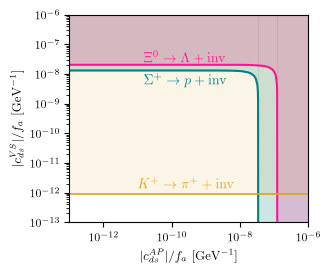

In [19]:
plt.loglog(contour_Sigma[1], contour_Sigma[0], label=r'$\Sigma^+ \to p a$', c='teal', lw=1.5)
plt.fill_between(contour_Sigma[1], contour_Sigma[0], 1e-6, color='teal', alpha=0.2, lw=0)
plt.fill_between([np.max(contour_Sigma[1]), 1e-6], y1=1e-13, y2=1e-6, color='teal', alpha=0.2, lw=0)
plt.loglog(contour_Xi[1], contour_Xi[0], label=r'$\Xi^0 \to \Lambda a$', c='deeppink', lw=1.5)
plt.fill_between(contour_Xi[1], contour_Xi[0], 1e-6, color='deeppink', alpha=0.2, lw=0)
plt.fill_between([np.max(contour_Xi[1]), 1e-6], y1=1e-13, y2=1e-6, color='deeppink', alpha=0.2, lw=0)
plt.loglog(contour_K[1], contour_K[0], label=r'$K^+ \to \pi^+ a$', c='goldenrod')
plt.fill_between(contour_K[1], contour_K[0], 1e-6, color='goldenrod', alpha=0.1, lw=0)

plt.text(1e-11, 1.4e-12, r'$K^+ \to \pi^+ + \mathrm{inv}$', fontsize=10, color='goldenrod')
plt.text(1.5e-11, 2.5e-8, r'$\Xi^0 \to \Lambda + \mathrm{inv}$', fontsize=10, color='deeppink')
plt.text(1.5e-11, 4.5e-9, r'$\Sigma^+ \to p + \mathrm{inv}$', fontsize=10, color='teal')

plt.xlim(1e-13, 1e-6)
plt.ylim(1e-13, 1e-6)

plt.xlabel(r'$|c_{ds}^{AP}|/f_a$ [GeV$^{-1}$]')
plt.ylabel(r'$|c_{ds}^{VS}|/f_a$ [GeV$^{-1}$]')

plt.tight_layout()
plt.savefig('baryons_inv.pdf', dpi=300, bbox_inches='tight')

In [24]:
chi2.citation_report('measurements_baryon_to_inv')